## Estimation

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Load the Tips dataset
tips = sns.load_dataset('tips')

In [3]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
tips.shape

(244, 7)

In [5]:
# Assume tips dataset as population
population_df = tips.copy()

### Example: Point estimation

1. Assume the **Tips Dataset** as the population.
2. Draw a random sample from the population.
3. Calculate the **Sample Mean** as the **Point Estimate** for the population mean.

In [6]:
# Draw a random sample from the population (e.g., sample size = 50)

sample_size = 50
sample_df = population_df.sample(n=sample_size, random_state=42)

In [7]:
sample_df.shape

(50, 7)

In [8]:
sample_df.head()

,total_bill,tip,sex,smoker,day,time,size
24,19.82,3.18,Male,No,Sat,Dinner,2
6,8.77,2.00,Male,No,Sun,Dinner,2
153,24.55,2.00,Male,No,Sun,Dinner,4
211,25.89,5.16,Male,Yes,Sat,Dinner,4
198,13.00,2.00,Female,Yes,Thur,Lunch,2


In [9]:
# Calculate the Population Mean of total bill for reference
population_mean = population_df['total_bill'].mean()

In [10]:
# Calculate the Sample Mean (Point Estimate)
sample_mean = sample_df['total_bill'].mean()

In [11]:
# Display Results
print(f"Population Mean (for reference): {population_mean:.2f}")
print(f"Point Estimate (Sample Mean): {sample_mean:.2f}")

Population Mean (for reference): 19.79
Point Estimate (Sample Mean): 17.97


<hr>

### Deciding sample size

The accuracy of estimating a population parameter, like the population mean, depends on the sample size. Larger samples lead to:
1. **More stable estimates** (reduced variability in sample means).
2. **Narrower confidence intervals**, making the estimate more precise.

In this exercise, we'll determine how sample size affects the estimation of the **mean age** in a population (the Tips Dataset) through visualization.


In [12]:
# Initialize list to store sample sizes and sample means

sample_means = []

for sample_size in np.arange(1,244):
    
     # Draw random sample of the given size
    sample_df = population_df.sample(n=sample_size)
    
    # Append sample size and sample mean
    sample_means.append((sample_size, sample_df['total_bill'].mean()))

In [13]:
# Create DataFrame to store results
sample_means_df = pd.DataFrame(sample_means, columns=['n', 'mean'])

In [14]:
# Display the first few rows of the DataFrame
sample_means_df.head()

,n,mean
0,1,20.290
1,2,16.375
2,3,19.550
3,4,18.225
4,5,22.868


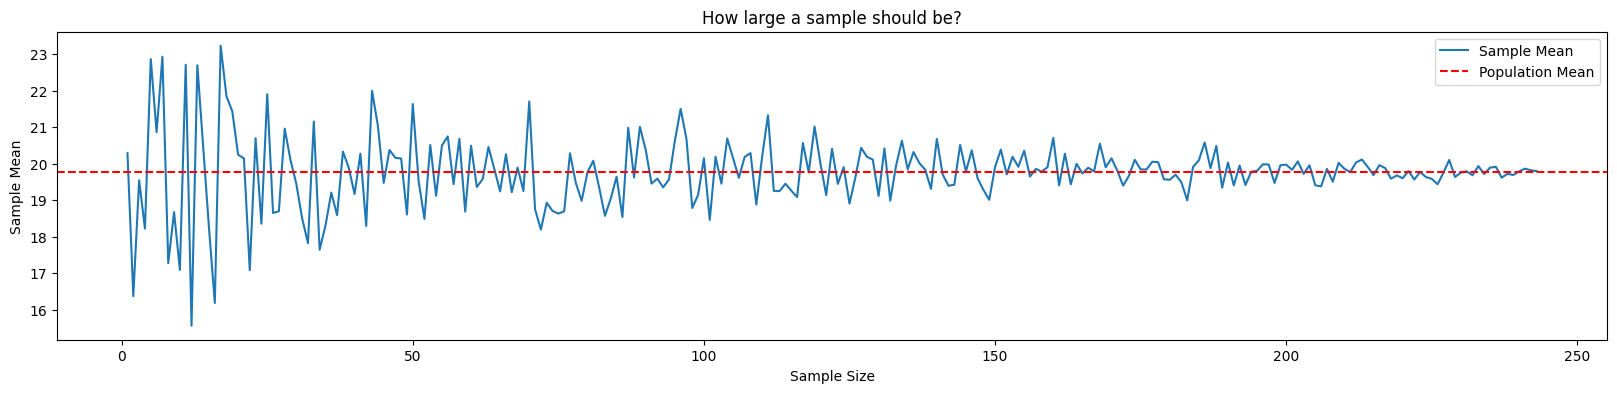

In [15]:
# Create the plot
fig, ax = plt.subplots(figsize=(20, 4))  # Set figure and axes size

# Add title and axis labels
ax.set_title("How large a sample should be?")
ax.set_xlabel('Sample Size')
ax.set_ylabel('Sample Mean')

# Plot line for sample mean
sns.lineplot(data=sample_means_df, x="n", y="mean", ax=ax, label="Sample Mean")

# Add horizontal line for population mean
ax.axhline(population_df['total_bill'].mean(), ls='--', color='red', label="Population Mean")

# Add legend
ax.legend()

# Show the plot
plt.show()

**Observations**

1. **Small Sample Sizes ($n \leq 30$)**:
   - Sample means fluctuate significantly due to higher variability.
   - Estimates are unreliable and deviate from the true population mean.

2. **Larger Sample Sizes ($n > 100$)**:
   - Sample means stabilize and converge toward the population mean due to the **Central Limit Theorem** (CLT).
   - Variability decreases significantly, making estimates more precise.

3. **Effectiveness of Large Samples**:
   - Larger samples better represent the population.
   - The sample mean becomes an accurate and reliable point estimate of the population mean.

### Sample Distributions of Sample Means
- Use the **Central Limit Theorem (CLT)** to estimate the population mean by drawing \(m = 1000\) samples of size \(n = 50\).

In [43]:
# Function to compute sampling distribution of sample means

def sampling_distribution(data, sample_size, number_of_samples):
    
    sample_means = []
    
    for i in range(number_of_samples):
        
        # Take a random sample of size `sample_size` from the population
        sample_df = data.sample(n=sample_size, replace=True)
        
        # Calculate the sample mean and store it
        sample_means.append(sample_df.mean())
        
    return pd.DataFrame({'mean': sample_means})

In [44]:
# Parameters
n = 50  # Sample size
m = 1000  # Number of samples

In [45]:
# Create the sampling distribution of sample means
sampling_distribution_df = sampling_distribution(data=population_df['total_bill'], sample_size=n, number_of_samples=m)

In [46]:
sampling_distribution_df.head()

,mean
0,20.4972
1,22.1352
2,21.7360
3,17.9348
4,21.4472


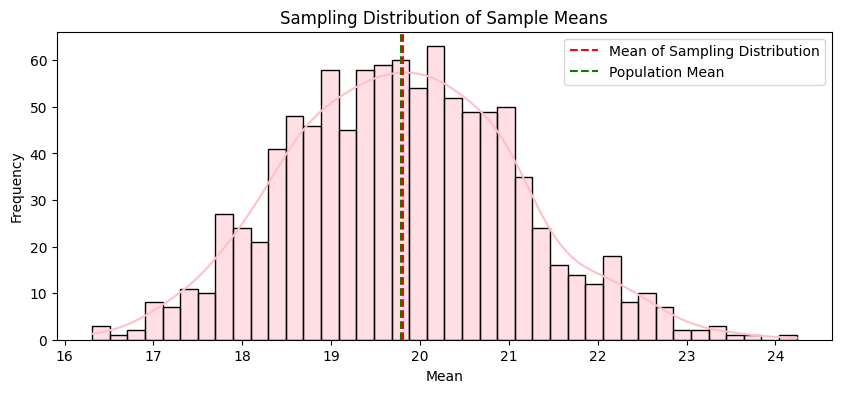

In [47]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title("Sampling Distribution of Sample Means")
ax.set_xlabel('Mean')
ax.set_ylabel('Frequency')
sns.histplot(sampling_distribution_df["mean"], bins=40, kde=True, ax=ax, color='pink')
ax.axvline(sampling_distribution_df["mean"].mean(), ls='--', color='red', label="Mean of Sampling Distribution")
ax.axvline(population_df['total_bill'].mean(), ls='--', color='green', label="Population Mean")
ax.legend()
plt.show()

In [48]:
# Display results
print(f"Mean of Sampling Distribution: {sampling_distribution_df['mean'].mean():.2f}.")
print(f"Population mean: {population_df['total_bill'].mean():.2f}.")

Mean of Sampling Distribution: 19.81.
Population mean: 19.79.
